In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, chi2_contingency

# Загружаем данные
df = pd.read_csv('../data/processed/kkbox_features.csv')

# Заполняем остатки
df['registered_via'] = df['registered_via'].fillna(0)
df['bd'] = df['bd'].fillna(df['bd'].median())


### Обработка возраста (bd)
Для возраста мы используем заполнение медианой, чтобы не терять данные при визуализации и не искажать распределение выбросами. Альтернативный подход — создание отдельной категории "Неизвестно" (например, -1), что может быть полезно при моделировании, но для целей EDA медиана является разумным компромиссом.

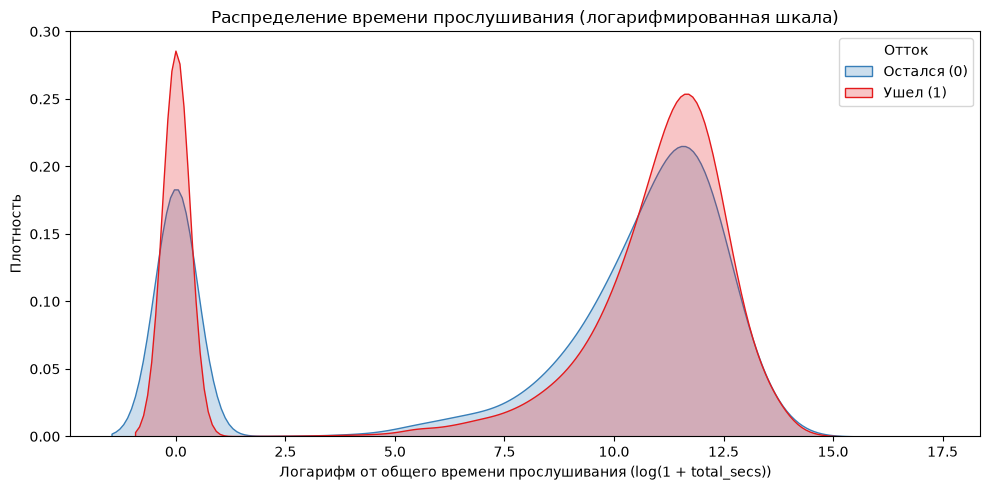

In [2]:
plt.figure(figsize=(10, 5))

# Вот эта строчка рисует сам график! (убедитесь, что она есть)
sns.kdeplot(data=df, x=np.log1p(df['total_secs']), hue='is_churn', fill=True, common_norm=False, palette='Set1')

plt.title('Распределение времени прослушивания (логарифмированная шкала)')
plt.xlabel('Логарифм от общего времени прослушивания (log(1 + total_secs))')
plt.ylabel('Плотность')
plt.legend(title='Отток', labels=['Остался (0)', 'Ушел (1)'])
plt.tight_layout()

# Сохраняем ПЕРЕД показом в папку images
plt.savefig('../images/churn_kde_plot.png', dpi=300, bbox_inches='tight')
plt.show()

In [3]:
# Разделяем на две группы
churned = df[df['is_churn'] == 1]['total_secs']
retained = df[df['is_churn'] == 0]['total_secs']

# Проверяем гипотезу: H0 - медианы равны, H1 - медиана у ушедших меньше
# Используем alternative='less', так как бизнес-логика подсказывает, 
# что уходящие пользователи слушают меньше
stat, p_value = mannwhitneyu(churned, retained, alternative='less')

print(f"Медиана total_secs у ушедших: {churned.median()}")
print(f"Медиана total_secs у оставшихся: {retained.median()}")
print(f"p-value: {p_value:.2e}") # Выводим в научном формате, так как p-value будет крошечным

Медиана total_secs у ушедших: 38419.619999999995
Медиана total_secs у оставшихся: 51167.386
p-value: 2.88e-127


  age_group      mean   count
0       <25  0.181366  135395
1     25-35  0.072175  751160
2     35-50  0.103850   71151
3       50+  0.086089   12731


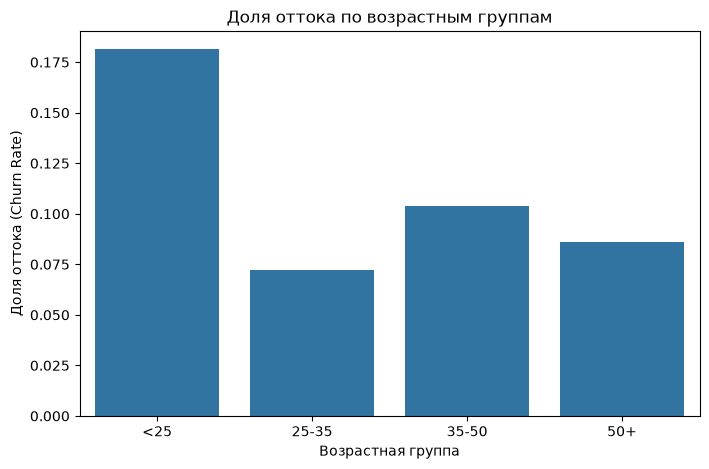

p-value (Chi-square): 0.0000


In [4]:
# Создаем возрастные группы
df['age_group'] = pd.cut(df['bd'], bins=[0, 25, 35, 50, 100], labels=['<25', '25-35', '35-50', '50+'])

# Считаем долю оттока в каждой группе
churn_by_age = df.groupby('age_group', observed=True)['is_churn'].agg(['mean', 'count']).reset_index()
print(churn_by_age)

# Строим барчарт
plt.figure(figsize=(8, 5))
sns.barplot(data=churn_by_age, x='age_group', y='mean')
plt.title('Доля оттока по возрастным группам')
plt.ylabel('Доля оттока (Churn Rate)')
plt.xlabel('Возрастная группа')

# Сохраняем ПЕРЕД показом, и указываем путь в папку images
plt.savefig('../images/churn_by_age.png', dpi=300, bbox_inches='tight')
plt.show() # И только теперь показываем

# Тест хи-квадрат
contingency_table = pd.crosstab(df['age_group'], df['is_churn'])
chi2, p_val_chi2, dof, expected = chi2_contingency(contingency_table)
print(f"p-value (Chi-square): {p_val_chi2:.4f}")



### Ключевые инсайты по драйверам оттока

1. **Активность — главный предиктор оттока.** 
   Медианное время прослушивания у оставшихся пользователей (51 167 сек.) в 1.3 раза выше, чем у ушедших (38 419 сек.). Разница статистически значима (Mann-Whitney U, p < 0.001). 
   *Бизнес-вывод:* Пользователи с низкой активностью в первые месяцы — главная группа риска. Необходимо стимулировать прослушивание (рекомендации, плейлисты) в первые недели.

2. **Молодая аудитория уходит чаще.**
   Доля оттока среди пользователей младше 25 лет составляет 18.1%, что в 2.5 раза выше, чем в группе 25-35 лет (7.2%). Разница значима (Chi-square, p < 0.001).
   *Бизнес-вывод:* Для удержания молодежи нужны специальные механики: студенческие тарифы, геймификация, интеграция с соцсетями.

### Матрица корреляций признаков
Для быстрой оценки силы и направления связи между признаками и целевой переменной построим матрицу корреляций. Это поможет выявить наиболее значимые признаки и потенциальную мультиколлинеарность.

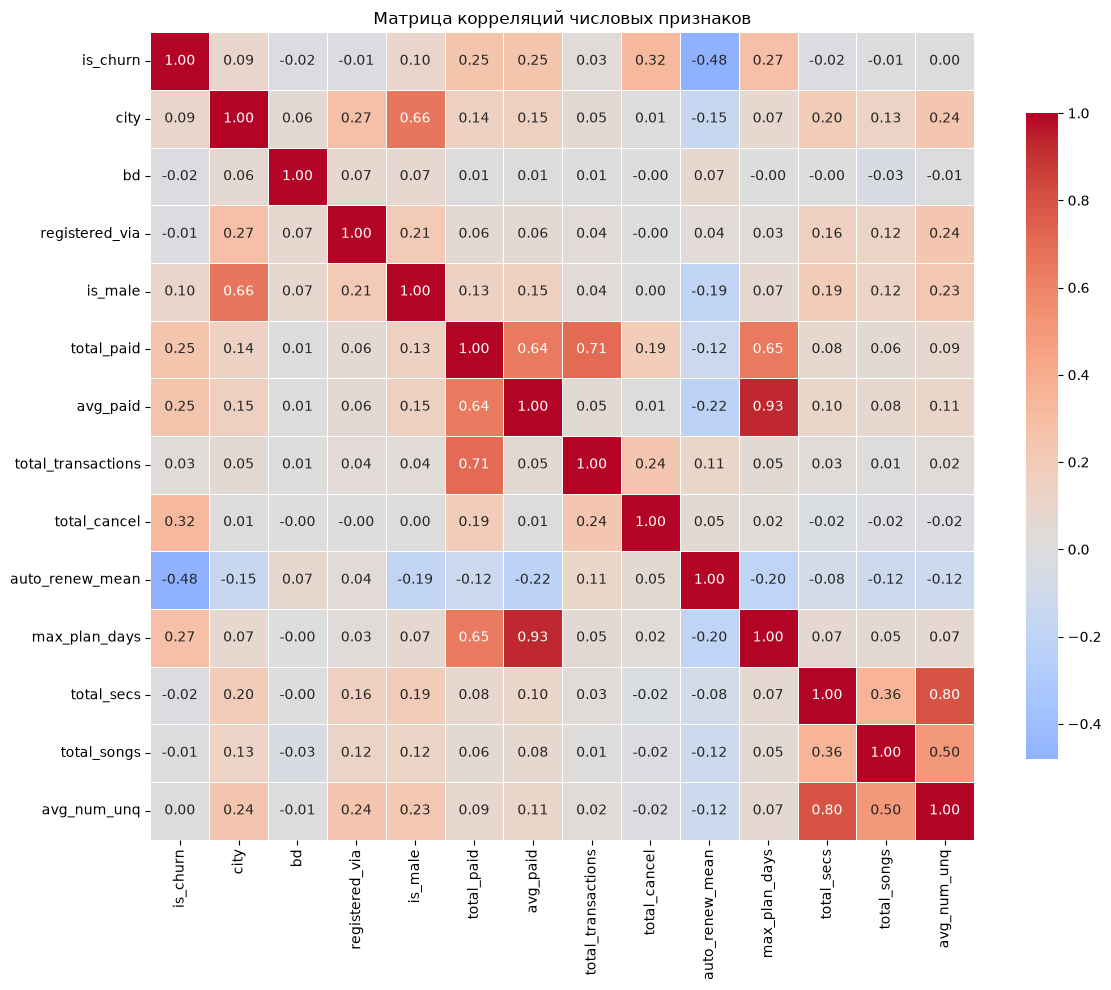

In [5]:
# Выбираем только числовые признаки для корреляции
# Убираем 'msno' и 'is_churn' из списка, но 'is_churn' нам нужен для анализа
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
corr_matrix = df[numeric_cols].corr()

# Строим тепловую карту корреляций
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', center=0, 
            linewidths=.5, cbar_kws={"shrink": .8})
plt.title('Матрица корреляций числовых признаков')
plt.tight_layout()

# Сохраняем ПЕРЕД показом
plt.savefig('../images/correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()